## Training Scripts ipynb Version

### **DISCLAIMER**
If you see this before you configure `total_timesteps` / `TOTAL_TIMESTEPS` to **5000000** (5 million), the **OUTPUT CELL** on this notebook does not reflect our `Final Reported Result`.

Default `total_timesteps` is set to **163840** on this notebook. Set `PPOConfig.total_timesteps` (Cell 5) or `TOTAL_TIMESTEPS` (Cell 10) to **5000000** before training to reproduce the final reported benchmark.

If you just want to see the final metrics, look at <a href="../docs/MASTER_DOC.md#bagian-vi-evaluasi-dan-hasil">Bagian VI: Evaluasi dan Hasil</a> in `docs/MASTER_DOC.md` instead.

In [45]:
from concurrent.futures import ProcessPoolExecutor, as_completed
from dataclasses import asdict, dataclass
from datetime import datetime
import multiprocessing as mp
from pathlib import Path
import sys

from IPython.display import Image, Markdown, display

from fly_traffic.config import (
    ConnectomeConfig,
    DEFAULT_ARTIFACTS_DIR,
    DEFAULT_DATASET_PATH,
    PROJECT_ROOT,
)
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from fly_traffic.connectome.artifact import ConnectomeArtifact
from fly_traffic.connectome.shuffled import (
    default_shuffled_connectome_path,
    load_or_create_shuffled_connectome,
)
from fly_traffic.training.ppo_trainer import PPOTrainer
from train_agents import copy_checkpoints, print_parameter_table, train_agent_worker

## 1. Configurations

In [18]:
DEFAULT_DATASET_PATH = PROJECT_ROOT / "dataset" / "connections_princeton.csv"
DEFAULT_ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

### 1.1 PPO Configurations

Konfigurasi PPO untuk pelatihan agen RL. Anda dapat menyesuaikan parameter ini sesuai kebutuhan.

In [30]:
@dataclass(frozen=True)
class PPOConfig:
    """Hyperparameters for recurrent and feedforward CPU PPO training."""
    total_timesteps: int = 163840
    num_envs: int = 8
    rollout_steps: int = 128
    sequence_chunk_len: int = 16
    num_minibatches: int = 4
    update_epochs: int = 4
    learning_rate: float = 8e-4
    gamma: float = 0.99
    gae_lambda: float = 0.95
    clip_coef: float = 0.2
    ent_coef: float = 0.005
    vf_coef: float = 0.25
    max_grad_norm: float = 0.5
    anneal_lr: bool = True
    seed: int = 42
    num_cpu_threads: int = 4
    checkpoints_dir: Path = DEFAULT_ARTIFACTS_DIR / "checkpoints"

### 1.2 Traffic Configurations
Konfigurasi lalu lintas untuk pelatihan agen RL. Anda dapat menyesuaikan parameter ini sesuai kebutuhan.

In [31]:
@dataclass(frozen=True)
class TrafficEnvConfig:
    """Configuration for the 4-way, 2-lane Gymnasium traffic environment."""
    dt_seconds: float = 2.0
    max_steps: int = 500
    max_lane_capacity: int = 30
    queue_obs_norm_capacity: float = 30.0
    hard_max_lane_capacity: int = 80
    straight_discharge_rate: float = 2.5
    turn_discharge_rate: float = 2.0
    min_green_steps: int = 6
    yellow_steps: int = 2
    all_red_steps: int = 1
    wait_penalty_alpha: float = 0.1
    switch_penalty_beta: float = 1.0
    reward_scale: float = 0.005
    max_wait_norm_seconds: float = 150.0
    max_elapsed_norm_steps: float = 20.0
    profile_name: str = "mixed"
    collision_penalty: float = 80.0
    red_light_wait_threshold_s: float = 150.0
    red_light_max_prob: float = 0.14
    dilemma_zone_prob: float = 0.18
    enable_collisions: bool = True

### 1.3 Other Configurations

Referensi konfigurasi tambahan pada repositori:
1. <a href="../src/fly_traffic/config.py">`src/fly_traffic/config.py`</a> — `ConnectomeConfig`, `BenchmarkConfig`, serta default `PPOConfig` dan `TrafficEnvConfig`.
2. <a href="../src/fly_traffic/agents/baselines.py">`src/fly_traffic/agents/baselines.py`</a> — arsitektur baseline `MLPBaselinePolicy` dan `GRUBaselinePolicy`.
3. <a href="../src/fly_traffic/environment/traffic_profiles.py">`src/fly_traffic/environment/traffic_profiles.py`</a> — profil kedatangan lalu lintas (`normal`, `asymmetric`, `asymmetric_ew`, `rush_hour`, `stress_train`, `stress_test`).

### 1.4 Training Configuration

In [32]:
AGENTS = ["fly", "fly_shuffled", "mlp", "gru"]

TOTAL_TIMESTEPS = PPOConfig.total_timesteps
NUM_ENVS = PPOConfig.num_envs
SEED = PPOConfig.seed
LR = PPOConfig.learning_rate

CONNECTOME_PATH = Path(ConnectomeConfig.output_path)
CHECKPOINTS_DIR = Path(PPOConfig.checkpoints_dir)

RESUME = True  # Resume from existing checkpoint in checkpoints_dir when available
PARALLEL_MODELS = 1  # Set 2..4 to train agents concurrently across CPU processes
SUFFIX = "_from_ipynb"  # Appended to "{agent}_ppo{SUFFIX}.pt"

conn_config = ConnectomeConfig(output_path=CONNECTOME_PATH)

artifact = None
if {"fly", "fly_shuffled"} & set(AGENTS):
    if not conn_config.output_path.exists():
        raise FileNotFoundError(
            f"Sub-connectome artifact not found at {conn_config.output_path}. "
            "Run scripts/extract_connectome.py first."
        )
    artifact = ConnectomeArtifact.load(conn_config.output_path)

print_parameter_table(AGENTS, artifact)

=== Policy Parameter Comparison (obs_dim=22, act_dim=4) ===
  FLY  | trainable=  70006 | total_params=  70006 | hidden_dim=2500
  FLY_SHUFFLED | trainable=  70006 | total_params=  70006 | hidden_dim=2500
  MLP  | trainable=  69755 | total_params=  69755 | hidden_dim=1
  GRU  | trainable=  69725 | total_params=  69725 | hidden_dim=105


## 2. Backup checkpoint lama

Backup bisa dilakukan dengan menyalin file `{agent}_ppo{SUFFIX}.pt` ke `backups/` dengan timestamp.

In [33]:
backup_dir = CHECKPOINTS_DIR / "backups"
backup_dir.mkdir(parents=True, exist_ok=True)

copy_checkpoints(
    agents=AGENTS,
    checkpoints_dir=CHECKPOINTS_DIR,
    suffix=SUFFIX,
    backup_dir=backup_dir,
    timestamp=datetime.now().strftime("%Y%m%d_%H%M%S"),
)

Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/fly_ppofrom_ipynb.pt
Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/fly_shuffled_ppofrom_ipynb.pt
Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/mlp_ppofrom_ipynb.pt
Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/gru_ppofrom_ipynb.pt


## 3. Source Code Arsitektur Agent 

Tinjau:
1. <a href="../src/fly_traffic/agents/baselines.py">`src/fly_traffic/agents/baselines.py`</a> untuk arsitektur agen RL (MLP dan GRU).
2. <a href="../src/fly_traffic/agents/fly_policy.py">`src/fly_traffic/agents/fly_policy.py`</a> untuk arsitektur Fly Connectome PPO.
3. <a href="../src/fly_traffic/agents/fixed_timer.py">`src/fly_traffic/agents/fixed_timer.py`</a> untuk arsitektur Fixed Timer (ini non trainable tapi bisa diubah manuual di situ).


## 4. Training Agents

### 4.1 Training sequential 
1 loop for each agent, train one by one

**only executed if `PARALLEL_MODELS = 1`**

In [34]:
if PARALLEL_MODELS < 2:
    trainer = PPOTrainer(
        ppo_config=PPOConfig(
            total_timesteps=TOTAL_TIMESTEPS,
            num_envs=NUM_ENVS,
            seed=SEED,
            checkpoints_dir=CHECKPOINTS_DIR,
            learning_rate=LR,
        ),
        env_config=TrafficEnvConfig(),
        connectome_config=conn_config,
    )

    for model_type in AGENTS:
        model_artifact = artifact
        if model_type == "fly_shuffled":
            model_artifact = load_or_create_shuffled_connectome(
                connectome_path=conn_config.output_path,
                shuffled_path=default_shuffled_connectome_path(conn_config.output_path),
            )

        filename = f"{model_type}_ppo{SUFFIX}.pt"
        ckpt = CHECKPOINTS_DIR / filename
        resume_from = ckpt if (RESUME and ckpt.exists()) else None

        print(
            f"\n--- {model_type.upper()} PPO | resume={resume_from is not None} | "
            f"{TOTAL_TIMESTEPS} steps | lr={LR} ---"
        )
        trainer.train(
            model_type=model_type,
            artifact=model_artifact,
            verbose=True,
            checkpoint_filename=filename,
            resume_from=resume_from,
            learning_rate=LR,
        )


--- FLY PPO | resume=False | 163840 steps | lr=0.0008 ---
[FLY] update=  1/160 steps=   1024 sps= 205.0 rew=-20.587 tp=   0.0 rew_iqm=-20.587 pg_loss=-0.0128 v_loss= 2.0501 ent=1.383
[FLY] update= 10/160 steps=  10240 sps= 210.4 rew=-126.222 tp= 656.4 rew_iqm=-112.387 pg_loss=-0.0177 v_loss= 1.1396 ent=1.309
[FLY] update= 20/160 steps=  20480 sps= 210.9 rew=-87.696 tp= 566.1 rew_iqm=-71.925 pg_loss=-0.0049 v_loss= 4.2125 ent=1.026
[FLY] update= 30/160 steps=  30720 sps= 210.7 rew=-85.523 tp= 602.9 rew_iqm=-69.116 pg_loss=-0.0128 v_loss= 0.6129 ent=0.889
[FLY] update= 40/160 steps=  40960 sps= 210.3 rew=-71.880 tp= 635.5 rew_iqm=-60.392 pg_loss=-0.0093 v_loss= 7.6531 ent=0.761
[FLY] update= 50/160 steps=  51200 sps= 211.8 rew=-72.606 tp= 677.6 rew_iqm=-60.410 pg_loss=-0.0056 v_loss= 0.6516 ent=0.652
[FLY] update= 60/160 steps=  61440 sps= 211.1 rew=-70.173 tp= 689.8 rew_iqm=-59.601 pg_loss=-0.0116 v_loss= 0.3594 ent=0.591
[FLY] update= 70/160 steps=  71680 sps= 211.3 rew=-67.926 tp= 67

### 4.2 Training paralel
ONLY executed if `PARALLEL_MODELS >= 2`

Training multiple agents in parallel, each agent has its own trainer. Set `RESUME = True` to continue from checkpoint.

In [ ]:
if PARALLEL_MODELS >= 2:
    max_workers = min(PARALLEL_MODELS, len(AGENTS))
    ppo_overrides = asdict(PPOConfig())
    env_overrides = asdict(TrafficEnvConfig())

    with ProcessPoolExecutor(
        max_workers=max_workers, mp_context=mp.get_context("spawn")
    ) as executor:
        futures = {
            executor.submit(
                train_agent_worker,
                model_type,
                TOTAL_TIMESTEPS,
                NUM_ENVS,
                SEED,
                CONNECTOME_PATH,
                CHECKPOINTS_DIR,
                SUFFIX,
                RESUME,
                LR,
                ppo_overrides,
                env_overrides,
            ): model_type
            for model_type in AGENTS
        }
        for future in as_completed(futures):
            model_type = futures[future]
            future.result()  # raise jika worker gagal
            print(f"[MAIN] {model_type.upper()} selesai.")

## 5. Benchmark & Evaluation

Evaluasi seluruh model terlatih bersama `FixedTimerAgent` pada 4 skenario (`normal`, `asymmetric`, `rush_hour`, `stress_test`, 10 seed), uji farmakologi & lesi, ekspor JSON/Markdown, serta render grafik.

In [36]:
from fly_traffic.agents.base import NeuralAgentAdapter
from fly_traffic.agents.baselines import load_policy_checkpoint
from fly_traffic.agents.fixed_timer import FixedTimerAgent
from fly_traffic.agents.fly_policy import FlyConnectomePolicy
from fly_traffic.config import BenchmarkConfig
from fly_traffic.evaluation.evaluator import AgentEvaluator
from fly_traffic.evaluation.visualizer import BenchmarkPlotter

BENCHMARK_OUTPUT_DIR = (
    Path(BenchmarkConfig.output_dir)
    if (TOTAL_TIMESTEPS >= 5_000_000 and SUFFIX == "")
    else Path(BenchmarkConfig.output_dir) / f"notebook_{TOTAL_TIMESTEPS}{SUFFIX}"
)
BENCHMARK_LABELS = {
    "fly": "Fly Connectome PPO",
    "fly_shuffled": "Shuffled Connectome PPO",
    "gru": "PPO-GRU",
    "mlp": "PPO-MLP",
}

shuffled_artifact = (
    load_or_create_shuffled_connectome(
        connectome_path=conn_config.output_path,
        shuffled_path=default_shuffled_connectome_path(conn_config.output_path),
    )
    if "fly_shuffled" in AGENTS
    else None
)

In [37]:
eval_agents = []
histories = {}
fly_policy = None

for model_type in AGENTS:
    ckpt_path = CHECKPOINTS_DIR / f"{model_type}_ppo{SUFFIX}.pt"
    if not ckpt_path.exists():
        print(f"Skipping missing checkpoint: {ckpt_path}")
        continue
    policy, payload = load_policy_checkpoint(
        path=ckpt_path,
        artifact=artifact if model_type == "fly" else None,
        shuffled_artifact=shuffled_artifact if model_type == "fly_shuffled" else None,
    )
    display_name = f"{BENCHMARK_LABELS[model_type]} ({ckpt_path.stem})"
    eval_agents.append(NeuralAgentAdapter(policy=policy, agent_name=display_name))
    if isinstance(payload.get("history"), dict):
        histories[display_name] = payload["history"]
    if model_type == "fly" and isinstance(policy, FlyConnectomePolicy):
        fly_policy = policy

eval_agents.append(FixedTimerAgent())

In [38]:
evaluator = AgentEvaluator(
    benchmark_config=BenchmarkConfig(output_dir=BENCHMARK_OUTPUT_DIR),
    env_config=TrafficEnvConfig(),
)

scenario_results = evaluator.evaluate_all_agents(eval_agents)
pharmacology_results = (
    evaluator.evaluate_pharmacology_and_lesions(fly_policy)
    if fly_policy is not None
    else []
)

Saved JSON report: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/benchmarks/benchmark_summary.json
Saved Markdown table: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/benchmarks/benchmark_table.md



## Results for **163840** steps

# Benchmark Evaluation Results

## Scenario Comparison

| Scenario | Agent | Mean Reward | Mean Queue | Mean Wait (s) | Mean Throughput | Mean Switches | Mean Collisions | Inference (ms/step) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| normal | Fly Connectome PPO (fly_ppofrom_ipynb) | -36.047 +/- 1.646 | 9.63 | 26.58 +/- 0.93 | 353.6 +/- 21.0 | 54.9 | 0.00 | 0.318 |
| normal | Shuffled Connectome PPO (fly_shuffled_ppofrom_ipynb) | -37.284 +/- 2.201 | 9.74 | 27.38 +/- 1.04 | 348.2 +/- 23.3 | 55.0 | 0.00 | 0.537 |
| normal | PPO-MLP (mlp_ppofrom_ipynb) | -37.825 +/- 2.123 | 9.88 | 27.06 +/- 0.90 | 356.2 +/- 23.5 | 51.5 | 0.00 | 0.240 |
| normal | PPO-GRU (gru_ppofrom_ipynb) | -338.292 +/- 35.812 | 82.98 | 261.71 +/- 32.09 | 136.2 +/- 15.3 | 4.1 | 39.80 | 0.312 |
| normal | Fixed Timer | -40.626 +/- 2.134 | 11.01 | 30.69 +/- 1.72 | 348.8 +/- 22.4 | 45.0 | 0.00 | 0.003 |
| asymmetric | Fly Connectome PPO (fly_ppofrom_ipynb) | -47.527 +/- 3.282 | 13.85 | 23.81 +/- 0.97 | 566.9 +/- 32.9 | 55.0 | 0.00 | 0.426 |
| asymmetric | Shuffled Connectome PPO (fly_shuffled_ppofrom_ipynb) | -50.742 +/- 2.917 | 14.83 | 25.82 +/- 0.72 | 557.3 +/- 31.5 | 54.5 | 0.00 | 0.419 |
| asymmetric | PPO-MLP (mlp_ppofrom_ipynb) | -54.384 +/- 3.823 | 14.49 | 24.84 +/- 0.70 | 567.5 +/- 22.0 | 46.3 | 0.10 | 0.120 |
| asymmetric | PPO-GRU (gru_ppofrom_ipynb) | -334.140 +/- 12.386 | 75.13 | 140.02 +/- 6.92 | 338.7 +/- 18.4 | 0.0 | 98.70 | 0.169 |
| asymmetric | Fixed Timer | -61.537 +/- 3.308 | 19.12 | 32.92 +/- 0.77 | 569.5 +/- 27.7 | 45.0 | 0.00 | 0.004 |
| rush_hour | Fly Connectome PPO (fly_ppofrom_ipynb) | -83.159 +/- 2.995 | 27.31 | 29.67 +/- 0.75 | 885.7 +/- 23.2 | 55.0 | 0.00 | 0.499 |
| rush_hour | Shuffled Connectome PPO (fly_shuffled_ppofrom_ipynb) | -83.560 +/- 4.734 | 27.09 | 29.34 +/- 0.73 | 890.0 +/- 36.4 | 53.8 | 0.00 | 0.441 |
| rush_hour | PPO-MLP (mlp_ppofrom_ipynb) | -81.916 +/- 3.228 | 25.91 | 28.25 +/- 1.12 | 886.1 +/- 19.8 | 53.9 | 0.00 | 0.129 |
| rush_hour | PPO-GRU (gru_ppofrom_ipynb) | -455.784 +/- 14.077 | 123.11 | 199.52 +/- 10.24 | 334.1 +/- 19.2 | 2.4 | 104.00 | 0.204 |
| rush_hour | Fixed Timer | -104.742 +/- 8.067 | 35.43 | 38.61 +/- 2.18 | 855.9 +/- 25.3 | 45.0 | 0.00 | 0.004 |
| stress_test | Fly Connectome PPO (fly_ppofrom_ipynb) | -386.369 +/- 14.918 | 137.59 | 85.73 +/- 3.00 | 1424.8 +/- 10.3 | 55.0 | 11.60 | 0.353 |
| stress_test | Shuffled Connectome PPO (fly_shuffled_ppofrom_ipynb) | -385.007 +/- 13.307 | 139.67 | 85.43 +/- 2.87 | 1451.8 +/- 11.8 | 54.3 | 5.20 | 0.446 |
| stress_test | PPO-MLP (mlp_ppofrom_ipynb) | -489.276 +/- 21.849 | 148.69 | 119.05 +/- 7.82 | 988.9 +/- 66.5 | 32.4 | 95.30 | 0.113 |
| stress_test | PPO-GRU (gru_ppofrom_ipynb) | -599.206 +/- 7.321 | 167.09 | 199.35 +/- 4.82 | 498.8 +/- 13.7 | 0.0 | 160.50 | 0.136 |
| stress_test | Fixed Timer | -365.067 +/- 17.968 | 126.19 | 76.47 +/- 3.09 | 1482.8 +/- 31.6 | 45.0 | 20.90 | 0.002 |

## Pharmacology and Lesioning Results (rush_hour)

| Condition | g_exc | g_inh | Active Neurons | Mean Reward | Mean Wait (s) | Mean Throughput | Mean Switches | Mean Collisions |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Baseline (g_exc=1.0, g_inh=1.0) | 1.00 | 1.00 | 2500 | -83.159 | 29.67 | 885.7 | 55.0 | 0.00 |
| High Excitation (g_exc=1.8, g_inh=1.0) | 1.80 | 1.00 | 2500 | -82.836 | 29.44 | 883.6 | 55.0 | 0.00 |
| Low Inhibition (g_exc=1.0, g_inh=0.2) | 1.00 | 0.20 | 2500 | -83.992 | 29.74 | 893.2 | 55.0 | 0.00 |
| High Inhibition (g_exc=1.0, g_inh=2.0) | 1.00 | 2.00 | 2500 | -83.170 | 29.69 | 885.1 | 55.0 | 0.00 |
| CX Lesion 25% | 1.00 | 1.00 | 2050 | -82.766 | 29.50 | 884.3 | 55.0 | 0.00 |
| MB Lesion 25% | 1.00 | 1.00 | 2325 | -83.276 | 29.72 | 878.8 | 55.0 | 0.00 |
| Random Lesion 25% | 1.00 | 1.00 | 1875 | -83.479 | 29.77 | 881.7 | 55.0 | 0.00 |


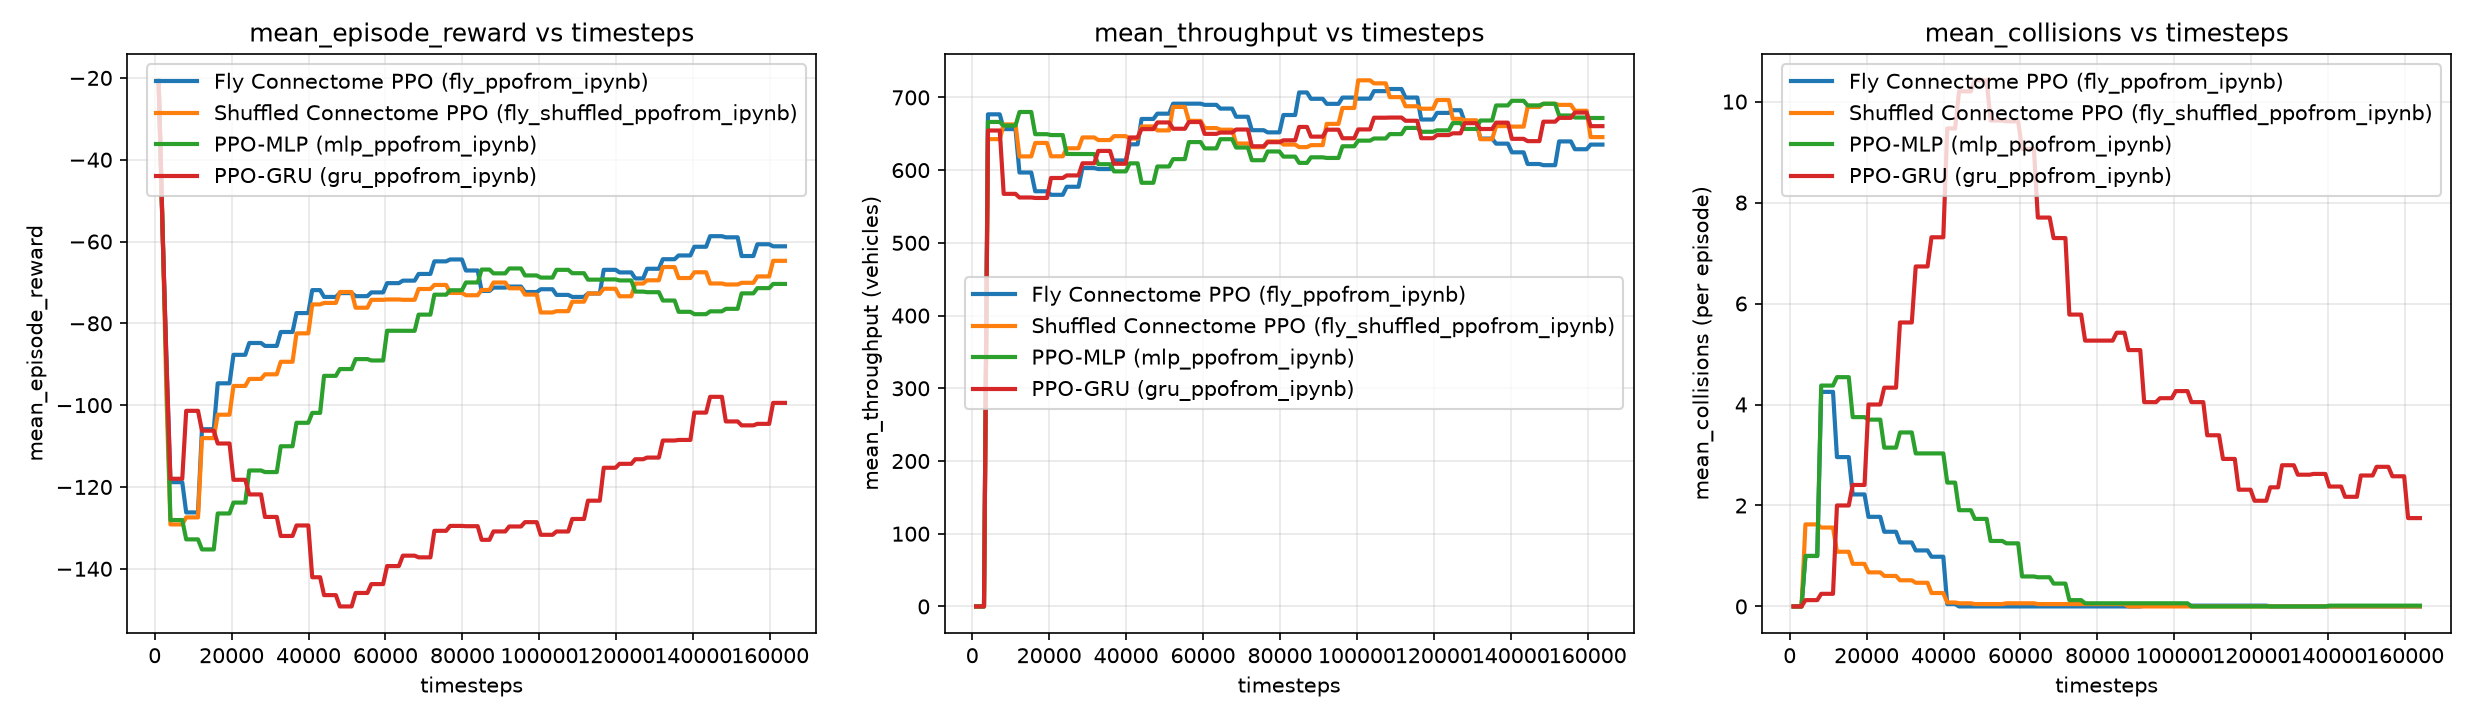

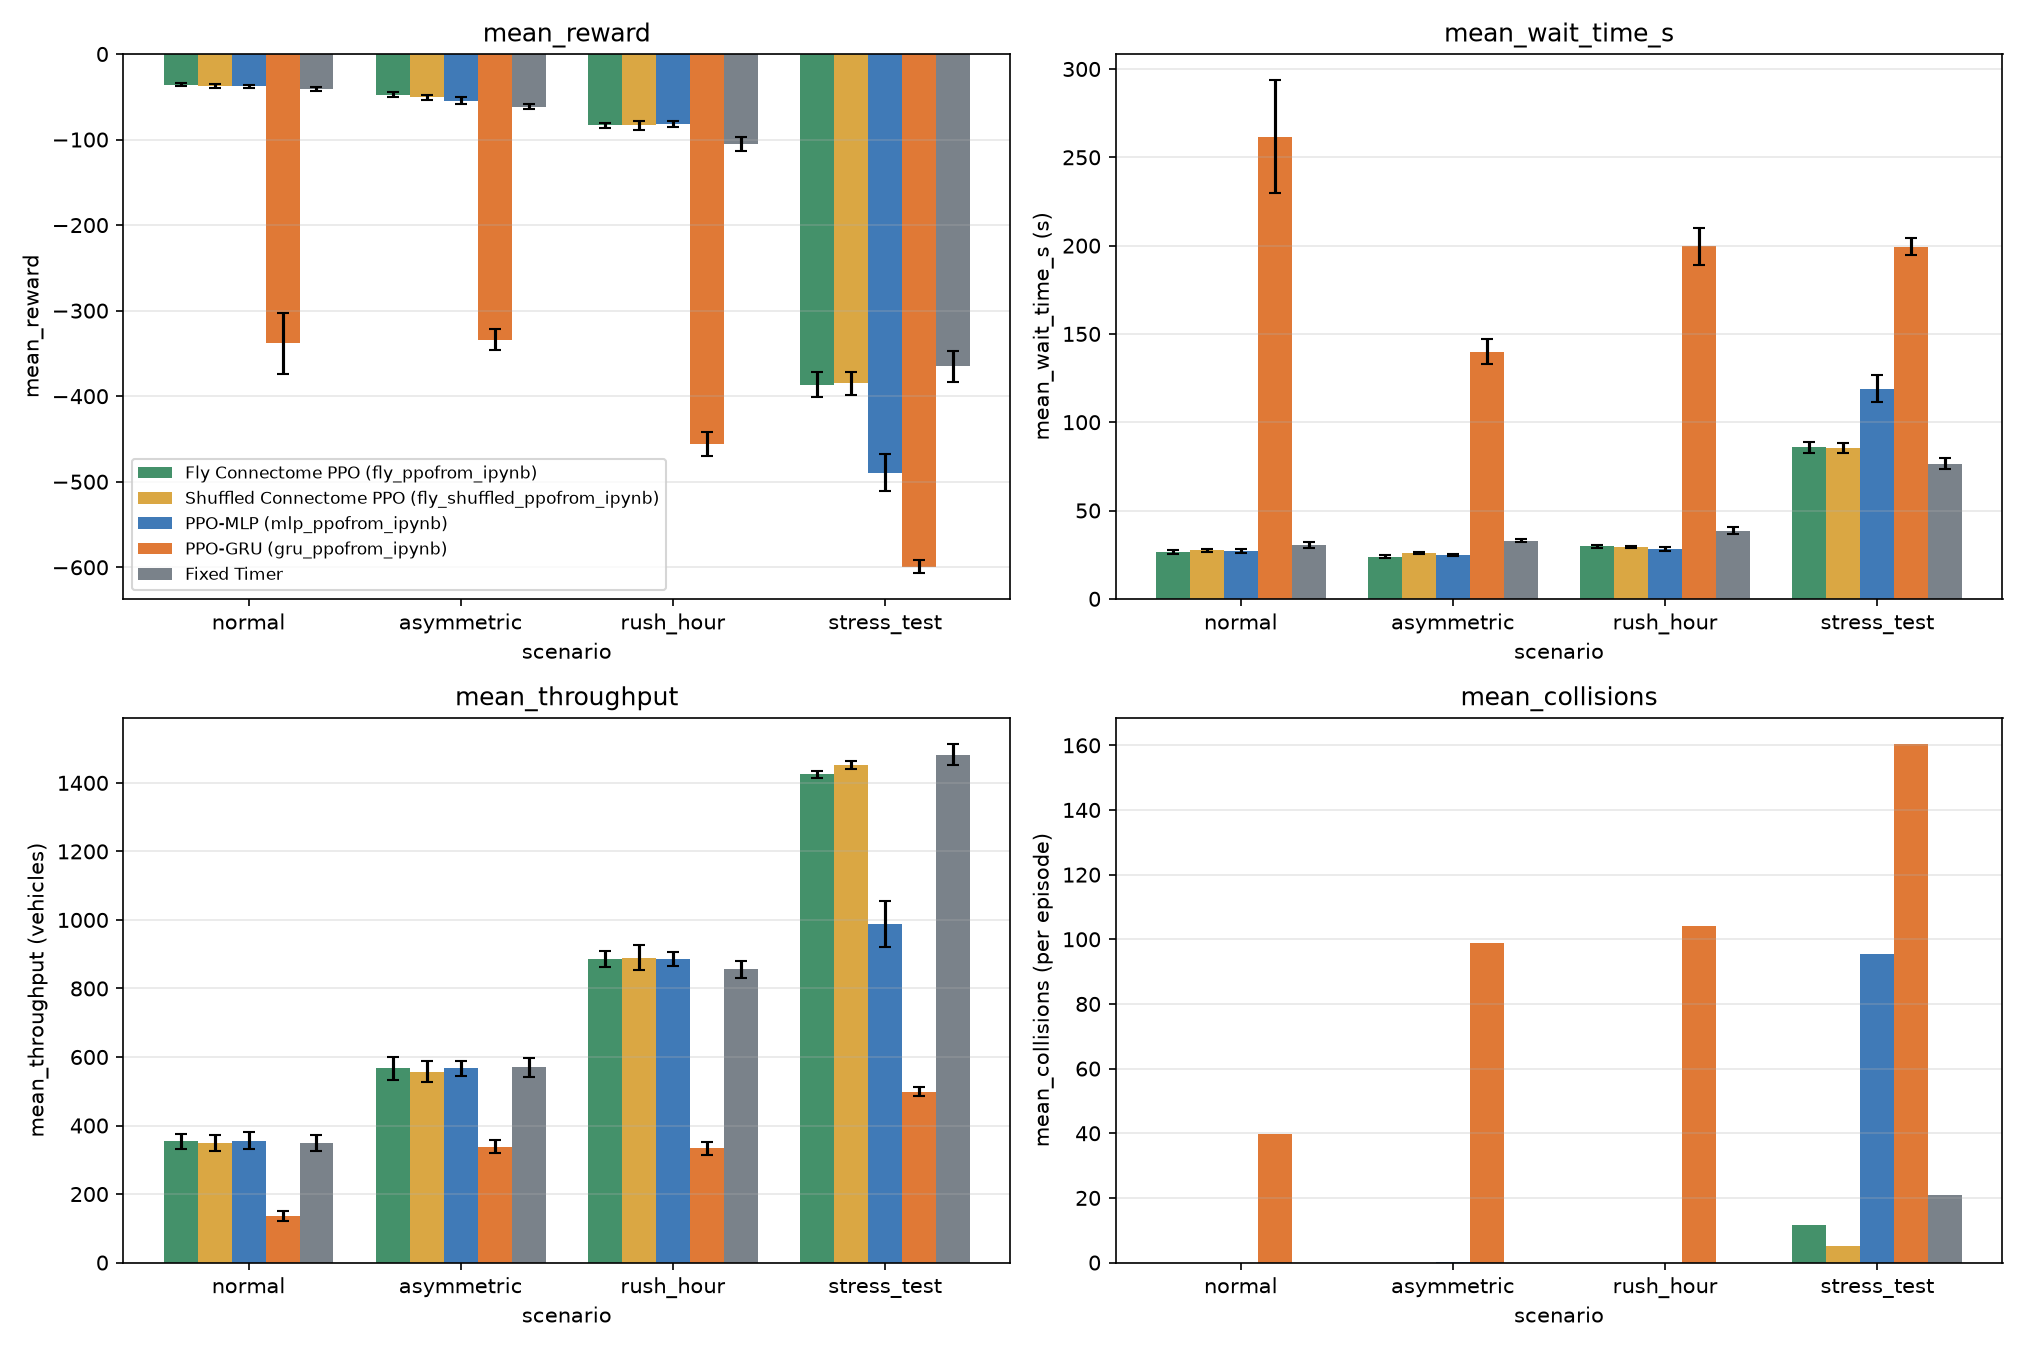

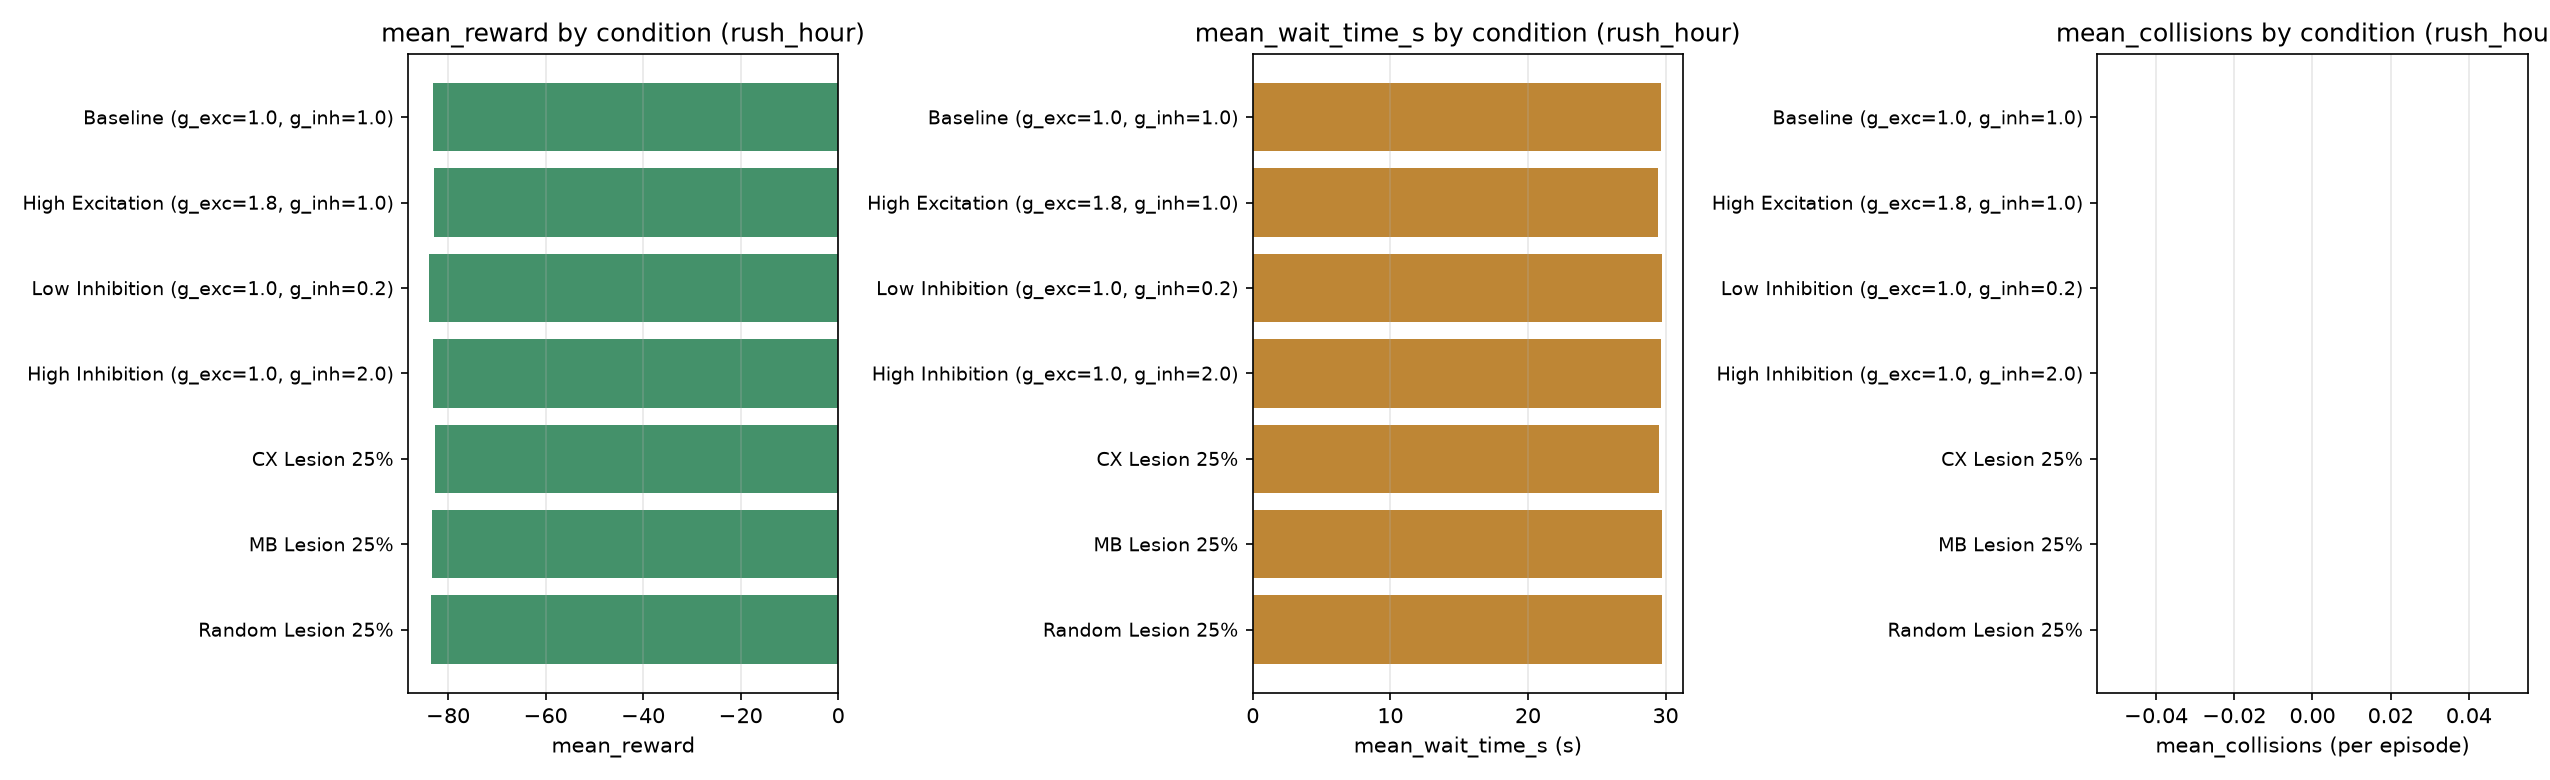

In [50]:
BENCHMARK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
json_path, md_path = evaluator.save_reports(
    output_dir=BENCHMARK_OUTPUT_DIR,
    scenario_results=scenario_results,
    pharmacology_results=pharmacology_results,
)

plot_paths = []
if histories:
    p_curves = BENCHMARK_OUTPUT_DIR / "training_curves.png"
    BenchmarkPlotter.plot_training_curves(histories=histories, output_path=p_curves)
    plot_paths.append(p_curves)

p_scenarios = BENCHMARK_OUTPUT_DIR / "scenario_comparison.png"
BenchmarkPlotter.plot_scenario_comparison(results=scenario_results, output_path=p_scenarios)
plot_paths.append(p_scenarios)

if pharmacology_results:
    p_pharma = BENCHMARK_OUTPUT_DIR / "pharmacology_ablation.png"
    BenchmarkPlotter.plot_pharmacology_ablation(results=pharmacology_results, output_path=p_pharma)
    plot_paths.append(p_pharma)

print(f"Saved JSON report: {json_path}")
print(f"Saved Markdown table: {md_path}\n")
display(Markdown(f"## Results for **{TOTAL_TIMESTEPS}** steps\n\n{md_path.read_text(encoding='utf-8')}"))

for fig_path in plot_paths:
    display(Image(filename=str(fig_path)))